In [1]:
import numpy as np

# Given parameters
a = 2.46          # Angstrom
d = a / np.sqrt(3)
t = -2.70         # eV

# Nearest-neighbor vectors
delta1 = d * np.array([0.0, 1.0])
delta2 = d * np.array([np.sqrt(3)/2, -1/2])
delta3 = d * np.array([-np.sqrt(3)/2, -1/2])

deltas = [delta1, delta2, delta3]

# Bloch sum f(k)
def f_k(k):
    f = 0.0 + 0.0j

    for delta in deltas:
        f += np.exp(1j * np.dot(k, delta))

    return f

# Single-layer Bloch Hamiltonian
def H_single_layer(k):
    f = f_k(k)

    H = np.array([
        [0.0,             t * f],
        [t * np.conj(f),  0.0]
    ], dtype=complex)

    return H

# Gamma point for verification
Gamma = np.array([0.0, 0.0])

# Calculate f(k)
f = f_k(Gamma)

# Analytic energies
E_analytic = np.array([
    -abs(t) * abs(f),
     abs(t) * abs(f)
])

# Numerical eigenvalues using eigvalsh
H = H_single_layer(Gamma)
E_numerical = np.linalg.eigvalsh(H)

print("f(Gamma) =", f)
print("|f(Gamma)| =", abs(f))

print("\nAnalytic energies (eV):")
print(E_analytic)

print("\nNumerical energies from np.linalg.eigvalsh (eV):")
print(E_numerical)

print("\nDifference:")
print(E_numerical - E_analytic)

f(Gamma) = (3+0j)
|f(Gamma)| = 3.0

Analytic energies (eV):
[-8.1  8.1]

Numerical energies from np.linalg.eigvalsh (eV):
[-8.1  8.1]

Difference:
[0. 0.]


In [2]:
import numpy as np
import pandas as pd

# Given parameters
a = 2.46          # Angstrom
d = a / np.sqrt(3)
t = -2.70         # eV

# Nearest-neighbor vectors
delta1 = d * np.array([0.0, 1.0])
delta2 = d * np.array([np.sqrt(3)/2, -1/2])
delta3 = d * np.array([-np.sqrt(3)/2, -1/2])

deltas = [delta1, delta2, delta3]

# Bloch sum
def f_k(k):
    f = 0.0 + 0.0j
    for delta in deltas:
        f += np.exp(1j * np.dot(k, delta))
    return f

# High-symmetry points
Gamma = np.array([0.0, 0.0])

K = np.array([
    4 * np.pi / (3 * a),
    0.0
])

M = np.array([
    np.pi / a,
    np.pi / (np.sqrt(3) * a)
])

points = {
    "Gamma": Gamma,
    "K": K,
    "M": M
}

results = []

for name, k in points.items():

    f = f_k(k)
    abs_f = abs(f)

    E_minus = -abs(t) * abs_f
    E_plus = abs(t) * abs_f

    results.append([
        name,
        abs_f,
        E_minus,
        E_plus
    ])

table = pd.DataFrame(
    results,
    columns=[
        "Point",
        "|f(k)|",
        "E_minus (eV)",
        "E_plus (eV)"
    ]
)

print(table.to_string(index=False))

Point       |f(k)|  E_minus (eV)  E_plus (eV)
Gamma 3.000000e+00 -8.100000e+00 8.100000e+00
    K 4.440892e-16 -1.199041e-15 1.199041e-15
    M 1.000000e+00 -2.700000e+00 2.700000e+00


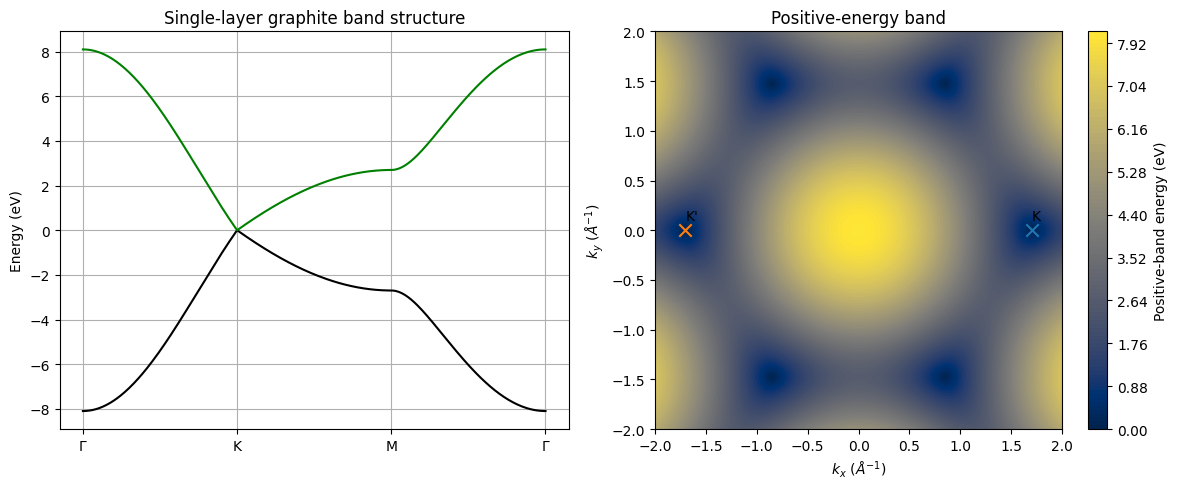

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
a = 2.46                  # Angstrom
d = a / np.sqrt(3)
t = -2.70                 # eV

# Nearest-neighbor vectors
delta1 = d * np.array([0.0, 1.0])
delta2 = d * np.array([np.sqrt(3)/2, -1/2])
delta3 = d * np.array([-np.sqrt(3)/2, -1/2])

deltas = [delta1, delta2, delta3]


# Bloch sum f(k)
def f_k(k):
    f = 0.0 + 0.0j

    for delta in deltas:
        f += np.exp(1j * np.dot(k, delta))

    return f


# Single-layer Hamiltonian
def H_single_layer(k):
    f = f_k(k)

    H = np.array([
        [0.0,             t * f],
        [t * np.conj(f),  0.0]
    ], dtype=complex)

    return H


# High-symmetry points
Gamma = np.array([0.0, 0.0])

K = np.array([
    4 * np.pi / (3 * a),
    0.0
])

M = np.array([
    np.pi / a,
    np.pi / (np.sqrt(3) * a)
])


# Function to generate points between two k-points
def make_path(k_start, k_end, N=100):

    path = []

    for x in np.linspace(0, 1, N, endpoint=False):
        k = (1 - x) * k_start + x * k_end
        path.append(k)

    return path


# Gamma -> K -> M -> Gamma
path = (
    make_path(Gamma, K) +
    make_path(K, M) +
    make_path(M, Gamma)
)

# Add final Gamma point
path.append(Gamma)

path = np.array(path)


# Calculate the two bands
energies = []

for k in path:
    H = H_single_layer(k)
    E = np.linalg.eigvalsh(H)
    energies.append(E)

energies = np.array(energies)


# Position along the k-path
x_path = np.arange(len(path))

N = 100

Gamma_position = 0
K_position = N
M_position = 2 * N
Gamma_final = 3 * N


# --------------------------
# Second panel: 2D positive band
# --------------------------

kx_values = np.linspace(-2.0, 2.0, 300)
ky_values = np.linspace(-2.0, 2.0, 300)

E_positive = np.zeros((len(ky_values), len(kx_values)))

for iy, ky in enumerate(ky_values):

    for ix, kx in enumerate(kx_values):

        k = np.array([kx, ky])

        H = H_single_layer(k)
        E = np.linalg.eigvalsh(H)

        E_positive[iy, ix] = E[1]


# Symmetry-related Dirac point
K_prime = np.array([
    -4 * np.pi / (3 * a),
    0.0
])


# --------------------------
# Plot
# --------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))


# Panel 1: band structure
axes[0].plot(x_path, energies[:, 0], color="black", label="Lower band")
axes[0].plot(x_path, energies[:, 1], color="green", label="Upper band")

axes[0].set_xticks([
    Gamma_position,
    K_position,
    M_position,
    Gamma_final
])

axes[0].set_xticklabels([
    r"$\Gamma$",
    "K",
    "M",
    r"$\Gamma$"
])

axes[0].set_ylabel("Energy (eV)")
axes[0].set_title("Single-layer graphite band structure")
axes[0].grid()


# Panel 2: positive-energy band
X, Y = np.meshgrid(kx_values, ky_values)

contour = axes[1].contourf(
    X,
    Y,
    E_positive,
    levels=100,
    cmap="cividis"
)

fig.colorbar(
    contour,
    ax=axes[1],
    label="Positive-band energy (eV)"
)

axes[1].scatter(K[0], K[1], marker="x", s=80)
axes[1].scatter(K_prime[0], K_prime[1], marker="x", s=80)

axes[1].text(K[0], K[1] + 0.1, "K")
axes[1].text(K_prime[0], K_prime[1] + 0.1, "K'")

axes[1].set_xlabel(r"$k_x$ ($\AA^{-1}$)")
axes[1].set_ylabel(r"$k_y$ ($\AA^{-1}$)")
axes[1].set_title("Positive-energy band")

plt.tight_layout()

plt.savefig(
    "graphite_problem1_task4.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [1]:
import numpy as np

a = 2.46                  # Angstrom
d = a / np.sqrt(3)        # Angstrom
t = -2.70                 # eV
hbar = 6.582119569e-16    # eV s

v_F = (3/2) * abs(t) * d * 1e-10 / hbar

print("d =", d, "Angstrom")
print("v_F =", v_F, "m/s")

d = 1.4202816622064793 Angstrom
v_F = 873904.0170323352 m/s


In [2]:
import numpy as np

a = 2.46
d = a / np.sqrt(3)
t = -2.70
gamma1 = 0.390

delta1 = d * np.array([0.0, 1.0])
delta2 = d * np.array([np.sqrt(3)/2, -1/2])
delta3 = d * np.array([-np.sqrt(3)/2, -1/2])

deltas = [delta1, delta2, delta3]

def f_k(k):
    f = 0.0 + 0.0j
    for delta in deltas:
        f += np.exp(1j * np.dot(k, delta))
    return f

def H_bilayer(k):
    f = f_k(k)

    H = np.array([
        [0.0,            t*f,             0.0,            0.0],
        [t*np.conj(f),   0.0,             gamma1,         0.0],
        [0.0,            gamma1,          0.0,            t*f],
        [0.0,            0.0,             t*np.conj(f),   0.0]
    ], dtype=complex)

    return H

# Example: Gamma point
Gamma = np.array([0.0, 0.0])

f = f_k(Gamma)
x = abs(t * f)

# Analytic energies
root = np.sqrt(x**2 + (gamma1/2)**2)

E_analytic = np.array([
    -root - gamma1/2,
    -root + gamma1/2,
     root - gamma1/2,
     root + gamma1/2
])

# Numerical energies
E_numerical = np.linalg.eigvalsh(H_bilayer(Gamma))

print("Analytic energies:")
print(E_analytic)

print("\nNumerical energies:")
print(E_numerical)

print("\nDifference:")
print(E_numerical - E_analytic)

Analytic energies:
[-8.29734688 -7.90734688  7.90734688  8.29734688]

Numerical energies:
[-8.29734688 -7.90734688  7.90734688  8.29734688]

Difference:
[ 0.00000000e+00 -8.88178420e-16  1.77635684e-15  1.77635684e-15]


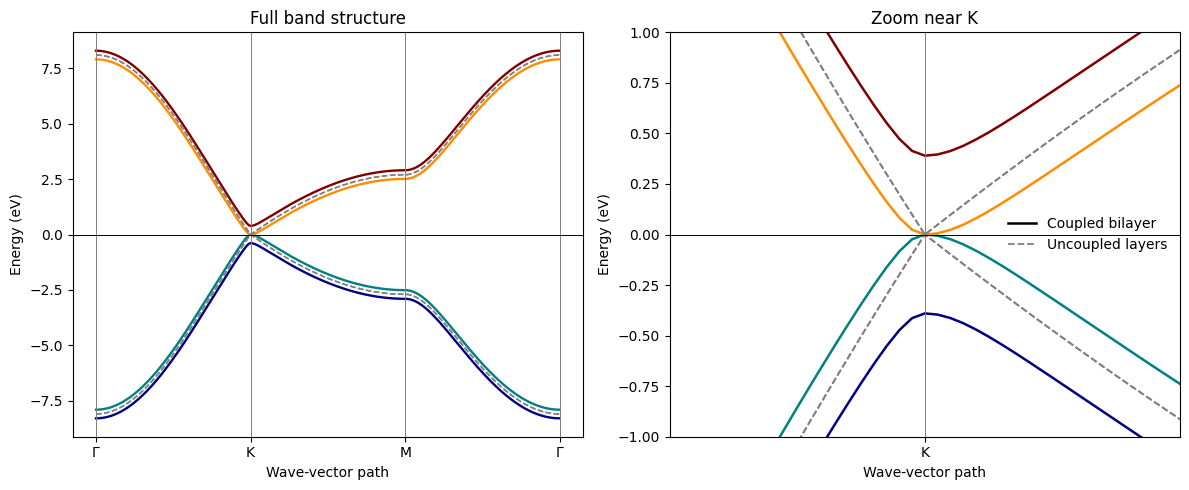

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
a = 2.46
d = a / np.sqrt(3)
t = -2.70
gamma1 = 0.390

# Nearest-neighbor vectors
delta1 = d * np.array([0.0, 1.0])
delta2 = d * np.array([np.sqrt(3)/2, -1/2])
delta3 = d * np.array([-np.sqrt(3)/2, -1/2])

deltas = [delta1, delta2, delta3]

def f_k(k):
    f = 0.0 + 0.0j
    for delta in deltas:
        f += np.exp(1j * np.dot(k, delta))
    return f

# Bilayer Hamiltonian
def H_bilayer(k, gamma):
    f = f_k(k)

    H = np.array([
        [0.0,            t*f,            0.0,          0.0],
        [t*np.conj(f),   0.0,            gamma,        0.0],
        [0.0,            gamma,          0.0,          t*f],
        [0.0,            0.0,            t*np.conj(f), 0.0]
    ], dtype=complex)

    return H

# High-symmetry points
Gamma = np.array([0.0, 0.0])
K = np.array([4*np.pi/(3*a), 0.0])
M = np.array([np.pi/a, np.pi/(np.sqrt(3)*a)])

# Create path
def make_path(start, end, N=100):
    points = []

    for x in np.linspace(0, 1, N, endpoint=False):
        points.append((1-x)*start + x*end)

    return points

path = (
    make_path(Gamma, K) +
    make_path(K, M) +
    make_path(M, Gamma)
)

path.append(Gamma)
path = np.array(path)

# Calculate energies
bands_coupled = []
bands_uncoupled = []

for k in path:

    # Coupled bilayer
    E1 = np.linalg.eigvalsh(H_bilayer(k, gamma1))
    bands_coupled.append(E1)

    # Two uncoupled layers: gamma1 = 0
    E2 = np.linalg.eigvalsh(H_bilayer(k, 0.0))
    bands_uncoupled.append(E2)

bands_coupled = np.array(bands_coupled)
bands_uncoupled = np.array(bands_uncoupled)

# x-axis
x = np.arange(len(path))

N = 100
ticks = [0, N, 2*N, 3*N]
labels = [r"$\Gamma$", "K", "M", r"$\Gamma$"]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# -------------------------
# Panel 1: Full band structure
# -------------------------

colors = ["navy", "teal", "darkorange", "maroon"]

for i in range(4):
    axes[0].plot(
        x,
        bands_coupled[:, i],
        color=colors[i],
        linewidth=1.7
    )

# Uncoupled layers
for i in range(4):
    axes[0].plot(
        x,
        bands_uncoupled[:, i],
        color="gray",
        linestyle="--",
        linewidth=1.1
    )

for xpos in ticks:
    axes[0].axvline(xpos, color="gray", linewidth=0.7)

axes[0].axhline(0, color="black", linewidth=0.7)

axes[0].set_xticks(ticks)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Energy (eV)")
axes[0].set_xlabel("Wave-vector path")
axes[0].set_title("Full band structure")


# -------------------------
# Panel 2: Zoom near K
# -------------------------

for i in range(4):
    axes[1].plot(
        x,
        bands_coupled[:, i],
        color=colors[i],
        linewidth=1.8
    )

for i in range(4):
    axes[1].plot(
        x,
        bands_uncoupled[:, i],
        color="gray",
        linestyle="--",
        linewidth=1.3
    )

axes[1].axvline(N, color="gray", linewidth=0.7)
axes[1].axhline(0, color="black", linewidth=0.7)

# Zoom around K
axes[1].set_xlim(N - 20, N + 20)
axes[1].set_ylim(-1.0, 1.0)

axes[1].set_xticks([N])
axes[1].set_xticklabels(["K"])

axes[1].set_xlabel("Wave-vector path")
axes[1].set_ylabel("Energy (eV)")
axes[1].set_title("Zoom near K")


# Common legend
axes[1].plot([], [], color="black",
             linewidth=1.8, label="Coupled bilayer")

axes[1].plot([], [], color="gray",
             linestyle="--",
             linewidth=1.3, label="Uncoupled layers")

axes[1].legend(frameon=False)

plt.tight_layout()

plt.savefig(
    "problem2_task3_bilayer_comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

  Energy (eV)           A1           B1           A2           B2
-3.900000e-01 4.726164e-30 5.000000e-01 5.000000e-01 4.726164e-30
-3.686408e-30 5.000000e-01 4.726164e-30 4.726164e-30 5.000000e-01
 3.686408e-30 5.000000e-01 4.726164e-30 4.726164e-30 5.000000e-01
 3.900000e-01 4.726164e-30 5.000000e-01 5.000000e-01 4.726164e-30


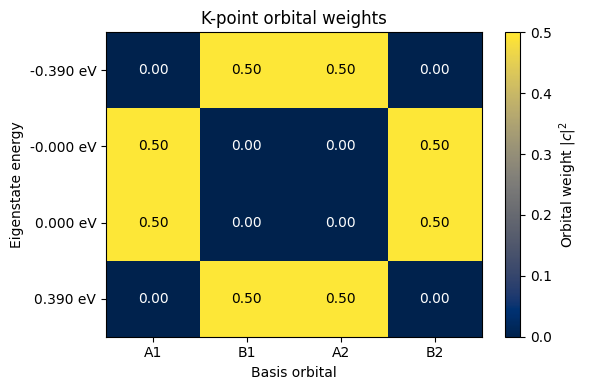

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# K point
K = np.array([4*np.pi/(3*a), 0.0])

# Hamiltonian at K
H_K = H_bilayer(K, gamma1)

# Eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(H_K)

# Orbital weights |c|^2
weights = np.abs(eigenvectors)**2

basis = ["A1", "B1", "A2", "B2"]

# Table
table = pd.DataFrame(
    weights.T,
    columns=basis
)

table.insert(0, "Energy (eV)", eigenvalues)

print(table.to_string(index=False))

# Heat map
plt.figure(figsize=(6, 4))

plt.imshow(
    weights.T,
    aspect="auto",
    cmap="cividis"
)

plt.colorbar(label=r"Orbital weight $|c|^2$")

plt.xticks(
    np.arange(4),
    basis
)

plt.yticks(
    np.arange(4),
    [f"{E:.3f} eV" for E in eigenvalues]
)

plt.xlabel("Basis orbital")
plt.ylabel("Eigenstate energy")
plt.title("K-point orbital weights")

# Write values on the heat map
for i in range(4):
    for j in range(4):

        value = weights[j, i]

        # White text on dark cells, black text on light cells
        text_color = "white" if value < 0.35 else "black"

        plt.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color
        )

plt.tight_layout()

plt.savefig(
    "problem2_task4_K_weights.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [5]:
import numpy as np

import numpy as np

a = 2.46
d = a / np.sqrt(3)
c = 6.70
t = -2.70
gamma1 = 0.390

delta1 = d * np.array([0.0, 1.0])
delta2 = d * np.array([np.sqrt(3)/2, -1/2])
delta3 = d * np.array([-np.sqrt(3)/2, -1/2])

deltas = [delta1, delta2, delta3]

def f_k(kx, ky):
    k = np.array([kx, ky])

    f = 0.0 + 0.0j

    for delta in deltas:
        f += np.exp(1j * np.dot(k, delta))

    return f

def g_kz(kz):
    return 2 * gamma1 * np.cos(kz * c / 2)

def H_graphite(kx, ky, kz):

    f = f_k(kx, ky)
    g = g_kz(kz)

    H = np.array([
        [0.0,            t*f,             0.0,            0.0],
        [t*np.conj(f),   0.0,             g,              0.0],
        [0.0,            g,               0.0,            t*f],
        [0.0,            0.0,             t*np.conj(f),   0.0]
    ], dtype=complex)

    return H
kx = 0.5
ky = 0.3
kz = 0.2

H = H_graphite(kx, ky, kz)

print("Hamiltonian:")
print(H)

hermiticity_error = np.max(np.abs(H - H.conj().T))

print("\nMaximum |H - H†| =", hermiticity_error)

Hamiltonian:
[[ 0.        +0.j         -6.76945899-0.18338574j  0.        +0.j
   0.        +0.j        ]
 [-6.76945899+0.18338574j  0.        +0.j          0.6113809 +0.j
   0.        +0.j        ]
 [ 0.        +0.j          0.6113809 +0.j          0.        +0.j
  -6.76945899-0.18338574j]
 [ 0.        +0.j          0.        +0.j         -6.76945899+0.18338574j
   0.        +0.j        ]]

Maximum |H - H†| = 0.0


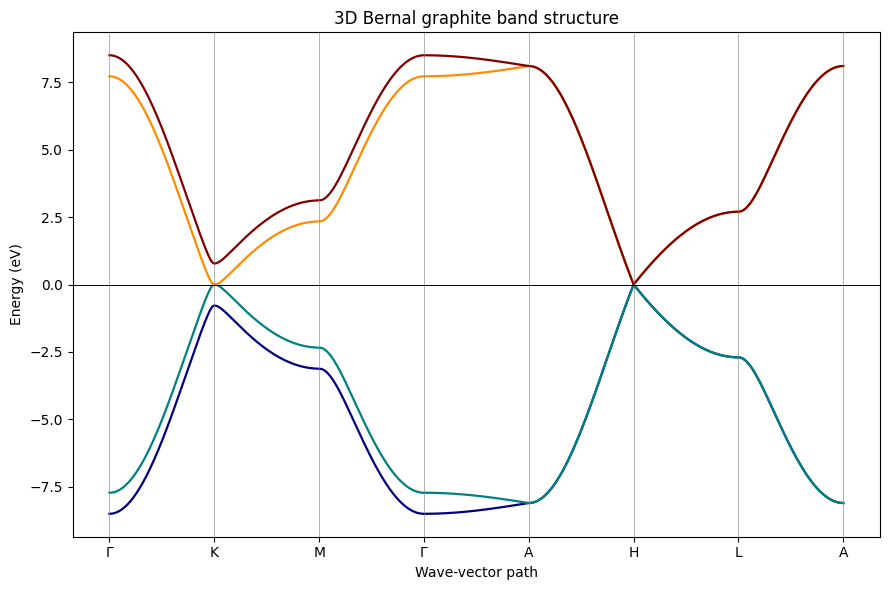

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
a = 2.46
d = a / np.sqrt(3)
c = 6.70
t = -2.70
gamma1 = 0.390

# Nearest-neighbor vectors
delta1 = d * np.array([0.0, 1.0])
delta2 = d * np.array([np.sqrt(3)/2, -1/2])
delta3 = d * np.array([-np.sqrt(3)/2, -1/2])

deltas = [delta1, delta2, delta3]


# In-plane Bloch sum
def f_k(kx, ky):
    k = np.array([kx, ky])

    f = 0.0 + 0.0j

    for delta in deltas:
        f += np.exp(1j * np.dot(k, delta))

    return f


# Vertical coupling
def g_kz(kz):
    return 2 * gamma1 * np.cos(kz * c / 2)


# 3D graphite Hamiltonian
def H_graphite(kx, ky, kz):

    f = f_k(kx, ky)
    g = g_kz(kz)

    H = np.array([
        [0.0,            t*f,             0.0,            0.0],
        [t*np.conj(f),   0.0,             g,              0.0],
        [0.0,            g,               0.0,            t*f],
        [0.0,            0.0,             t*np.conj(f),   0.0]
    ], dtype=complex)

    return H


# High-symmetry points
Gamma = np.array([0.0, 0.0, 0.0])

K = np.array([
    4*np.pi/(3*a),
    0.0,
    0.0
])

M = np.array([
    np.pi/a,
    np.pi/(np.sqrt(3)*a),
    0.0
])

A = np.array([
    0.0,
    0.0,
    np.pi/c
])

H_point = np.array([
    4*np.pi/(3*a),
    0.0,
    np.pi/c
])

L = np.array([
    np.pi/a,
    np.pi/(np.sqrt(3)*a),
    np.pi/c
])


# Build path between two points
def make_path(start, end, N=100):

    points = []

    for x in np.linspace(0, 1, N, endpoint=False):
        points.append((1-x)*start + x*end)

    return points


# Gamma -> K -> M -> Gamma -> A -> H -> L -> A
vertices = [
    Gamma,
    K,
    M,
    Gamma,
    A,
    H_point,
    L,
    A
]

path = []

for i in range(len(vertices)-1):
    path += make_path(vertices[i], vertices[i+1])

path.append(A)

path = np.array(path)


# Calculate four energy bands
bands = []

for k in path:

    Hmat = H_graphite(
        k[0],
        k[1],
        k[2]
    )

    E = np.linalg.eigvalsh(Hmat)
    bands.append(E)

bands = np.array(bands)


# x-axis positions
x = np.arange(len(path))

N = 100

ticks = [
    0,
    N,
    2*N,
    3*N,
    4*N,
    5*N,
    6*N,
    7*N
]

labels = [
    r"$\Gamma$",
    "K",
    "M",
    r"$\Gamma$",
    "A",
    "H",
    "L",
    "A"
]


# Plot
plt.figure(figsize=(9, 6))

colors = ["navy", "teal", "darkorange", "maroon"]

for i in range(4):
    plt.plot(
        x,
        bands[:, i],
        color=colors[i],
        linewidth=1.6
    )

# High-symmetry vertical lines
for xpos in ticks:
    plt.axvline(
        xpos,
        color="gray",
        linewidth=0.7,
        alpha=0.6
    )

plt.axhline(
    0,
    color="black",
    linewidth=0.7
)

plt.xticks(ticks, labels)

plt.xlabel("Wave-vector path")
plt.ylabel("Energy (eV)")
plt.title("3D Bernal graphite band structure")

plt.tight_layout()

plt.savefig(
    "problem3_task2_graphite_bands.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [7]:
# K point
K_bulk = np.array([
    4*np.pi/(3*a),
    0.0,
    0.0
])

# H point
H_bulk = np.array([
    4*np.pi/(3*a),
    0.0,
    np.pi/c
])

E_K = np.linalg.eigvalsh(
    H_graphite(K_bulk[0], K_bulk[1], K_bulk[2])
)

E_H = np.linalg.eigvalsh(
    H_graphite(H_bulk[0], H_bulk[1], H_bulk[2])
)

print("K-point energies =", E_K)
print("H-point energies =", E_H)

K-point energies = [-7.80000000e-01 -1.84320385e-30  1.84320385e-30  7.80000000e-01]
H-point energies = [-1.22315926e-15 -1.17539804e-15  1.17539804e-15  1.22315926e-15]


In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Reciprocal lattice vectors
b1 = np.array([
    2*np.pi/a,
    2*np.pi/(np.sqrt(3)*a),
    0.0
])

b2 = np.array([
    -2*np.pi/a,
    2*np.pi/(np.sqrt(3)*a),
    0.0
])

b3 = np.array([
    0.0,
    0.0,
    2*np.pi/c
])


# Shifted uniform mesh
N = 30

fractional = (np.arange(N) + 0.5)/N - 0.5

energies = []

for u1 in fractional:
    for u2 in fractional:
        for u3 in fractional:

            k = u1*b1 + u2*b2 + u3*b3

            E = np.linalg.eigvalsh(
                H_graphite(k[0], k[1], k[2])
            )

            energies.extend(E)

energies = np.array(energies)

Nk = N**3

print("Mesh =", N, "x", N, "x", N)
print("Number of k-points =", Nk)
print("Number of sampled energies =", len(energies))

Mesh = 30 x 30 x 30
Number of k-points = 27000
Number of sampled energies = 108000


In [10]:
# Gaussian broadening
sigma = 0.08   # eV

# Energy axis
Emin = energies.min() - 5*sigma
Emax = energies.max() + 5*sigma

Egrid = np.linspace(Emin, Emax, 1200)

DOS = np.zeros_like(Egrid)

# Each spinless state has weight 1/Nk
weight = 1.0 / Nk

for En in energies:

    gaussian = (
        np.exp(-(Egrid - En)**2 / (2*sigma**2))
        /
        (sigma*np.sqrt(2*np.pi))
    )

    DOS += weight * gaussian
    integrated_DOS = np.trapz(DOS, Egrid)

print("Gaussian broadening =", sigma, "eV")
print("Integrated DOS =", integrated_DOS)

/tmp/ipykernel_1239/3609077763.py:24: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integrated_DOS = np.trapz(DOS, Egrid)


Gaussian broadening = 0.08 eV
Integrated DOS = 3.9999999997148135


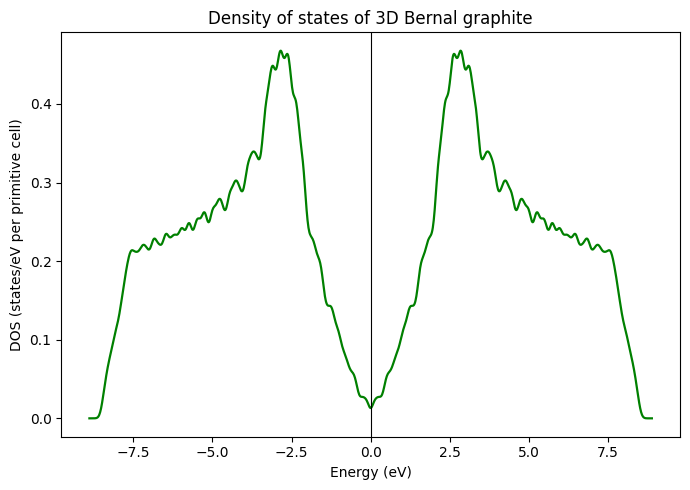

In [12]:
plt.figure(figsize=(7,5))

plt.plot(
    Egrid,
    DOS,
    color="green",
    linewidth=1.6
)

plt.axvline(
    0,
    color="black",
    linewidth=0.8
)

plt.xlabel("Energy (eV)")
plt.ylabel("DOS (states/eV per primitive cell)")
plt.title("Density of states of 3D Bernal graphite")

plt.tight_layout()

plt.savefig(
    "problem3_task4_DOS.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()